# PSO Funnel — Exploratory Data Analysis

Handshake AI case study. Three questions:

1. Where does the PSO funnel lose people?
2. Which drop-off matters most, what drives it, and what should we do?
3. Where should the likeness agreement step go?

The unit of analysis is a **PSO instance** = one `(tasker_id, project_id)` pair. Taskers
onboard onto several projects at once and sit at different steps in each, so the tasker
is the wrong grain. All cleaning lives in `src/pso_clean.py` so the dashboard and this
notebook cannot disagree.

In [1]:
import sys
sys.path.insert(0, "../src")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pso_clean as pc

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

PATH = "../" + pc.DATA_FILE

# A peek at the raw shape. The full 312k-row frame is never materialised: the
# quality checks below stream the file and the analysis runs on the 54k-row
# instance table, which keeps this notebook cheap to re-run.
pd.read_csv(PATH, nrows=3)

,event_id,tasker_id,project_id,project_name,event_name,event_ts,device,tasker_tenure,prior_projects_completed,country,concurrent_psos,assessment_est_minutes,likeness_variant,properties
0,evt_469680ad81d3,tsk_39873445,prj_1037,Cobalt,pso_allocated,2026-06-01T00:06:38Z,NaN,new,0,CA,1,45,NaN,NaN
1,evt_1397be792b2c,tsk_f34513e7,prj_1000,Juniper,pso_allocated,2026-06-01T00:06:55Z,NaN,new,0,DE,1,20,NaN,NaN
2,evt_03daf4392807,tsk_b1f9f4ce,prj_1111,Halcyon,pso_allocated,2026-06-01T00:10:29Z,NaN,returning,1,US,1,60,NaN,NaN


## 1. Data quality

The brief says this is the export "as it came out of the pipeline", so check it before
trusting it.

In [2]:
qa = pc.raw_quality_report(PATH)
print(f"raw rows              : {qa['total_rows']:,}")
print(f"exact duplicate rows  : {qa['duplicate_rows']:,}")
print(f"duplicate event_ids   : {qa['duplicate_event_ids']:,}")
print("every duplicate event_id is a fully identical row:",
      qa["every_duplicate_id_is_an_identical_row"])

raw rows              : 315,269
exact duplicate rows  : 3,121
duplicate event_ids   : 3,121
every duplicate event_id is a fully identical row: True


Every repeated `event_id` is a byte-identical row, so this is a pipeline replay rather than
two real occurrences. Dropping them removes 3,121 rows and shifts every count downstream.

In [3]:
print("--- device: raw values ---")
for k, v in qa["device_counts"].items():
    print(f"  {k:10s} {v:7,}  -> {pc.DEVICE_MAP.get(k, '(dropped)')}")
print()
print("--- nulls by column ---")
for k, v in qa["null_counts"].items():
    print(f"  {k:24s} {v:7,}")

--- device: raw values ---
  (null)     189,801  -> (dropped)
  mobile      41,389  -> mobile
  desktop     36,587  -> desktop
  iOS         13,369  -> mobile
  Mobile      11,183  -> mobile
  Android      8,932  -> mobile
  Desktop      5,485  -> desktop
  web          3,633  -> desktop
  tablet       2,924  -> tablet
  iPad         1,966  -> tablet

--- nulls by column ---
  likeness_variant         243,274
  properties               189,993
  device                   189,801


`device` mixes casing, operating system and form factor (`mobile`/`Mobile`/`iOS`/`Android`
are all one thing). `pso_clean.DEVICE_MAP` collapses the ten raw values to mobile / desktop
/ tablet. It is null on ~60% of rows because the pipeline only captures it on interactive
events, not on server-side ones like `email_delivered`.

In [4]:
records, stats = pc.build_instance_records(PATH)
print(pc.validate_records(records, stats))

inst = pc.build_instances(records=records)
print(f"\ninstance table: {inst.shape[0]:,} rows x {inst.shape[1]} columns")

print(records[1]['accept_source'])
# print(f"stats: {stats}")

{'events_deduped': 312148, 'duplicate_rows_dropped': 3121, 'instances': 53935, 'taskers': 30025, 'projects': 12, 'out_of_order_transitions': 0}



instance table: 53,935 rows x 54 columns
None


In [5]:
accept_sources = []
for record in records:
    source = record['accept_source']
    if source not in accept_sources:
        accept_sources.append(source)
print(accept_sources)

[None, 'email', 'in_app']


In [6]:
# Timestamps: do any funnel steps arrive out of order?
violations = {
    f"{later} before {earlier}": int((inst[f"ts_{later}"] < inst[f"ts_{earlier}"]).sum())
    for earlier, later in zip(pc.FUNNEL_STEPS, pc.FUNNEL_STEPS[1:])
}
print("out-of-order transitions:", {k: v for k, v in violations.items() if v} or "none")
print(f"window: {stats['ts_min']}  ->  {stats['ts_max']}")

out-of-order transitions: none
window: 2026-06-01T00:06:38Z  ->  2026-08-31T23:59:48Z


Timestamps are clean: all parse, all sit inside the stated June 1 – August 31 window, and
no step is ever recorded before the step preceding it. So we can order the funnel by step
definition and do not need to repair sequences.

In [7]:
# Email open/click tracking gaps.
accepted = inst["reached_pso_accepted"]
no_open = int((accepted & ~inst["reached_email_opened"]).sum())
no_click = int((accepted & ~inst["reached_email_clicked"]).sum())
print(f"Total accepted: {int(accepted.sum())}")
print(f"accepted with no recorded email_opened : {no_open:,}")
print(f"accepted with no recorded email_clicked: {no_click:,}")
print()
print(inst.loc[accepted, "accept_source"].value_counts().to_string())
print()
print("event counts in the RAW file:")
for k, v in qa["event_counts"].items():
    print(f"  {k:34s} {v:7,}")

Total accepted: 21242
accepted with no recorded email_opened : 2,311
accepted with no recorded email_clicked: 1,701

accept_source
email     19541
in_app     1701

event counts in the RAW file:
  pso_allocated                       54,473
  email_sent                          53,635
  email_delivered                     51,594
  email_opened                        30,301
  email_clicked                       22,805
  pso_accepted                        21,468
  confidentiality_agreement_signed    19,664
  assessment_started                  18,369
  assessment_attempted                 9,749
  assessment_passed                    6,361
  contract_started                     5,996
  pso_completed                        5,569
  contract_finished                    5,568
  first_task_claimed                   3,613
  first_task_submitted                 3,128
  likeness_agreement_signed            2,638
  likeness_agreement_declined            338


In [8]:
# allocated_dedup = inst.drop_duplicates()
# # print(allocated.sum())

In [9]:
# allocated = allocated_dedup['reached_pso_allocated'].sum()
# print(allocated)

**This matters for reading the funnel.** 2,311 instances accepted without a recorded open
and 1,701 without a recorded click — and 1,701 accepted `in_app`, never touching the email
at all. Open pixels are blocked by most mail clients, so `email_delivered → email_opened`
is part measurement artifact and part real loss, and nothing in this data separates the two.
Any conclusion resting on that step would be unsafe.

## 2. The funnel

In [10]:
funnel = pc.funnel_table(inst)
funnel

,reached,step_conversion_pct,lost_at_step,pct_of_allocated
pso_allocated,53935,NaN,NaN,100.0
email_sent,53082,98.4,853.0,98.4
email_delivered,51123,96.3,1959.0,94.8
email_opened,29984,58.7,21139.0,55.6
email_clicked,22595,75.4,7389.0,41.9
pso_accepted,21242,94.0,1353.0,39.4
confidentiality_agreement_signed,19483,91.7,1759.0,36.1
assessment_started,16720,85.8,2763.0,31.0
assessment_attempted,9653,57.7,7067.0,17.9
assessment_passed,6300,65.3,3353.0,11.7


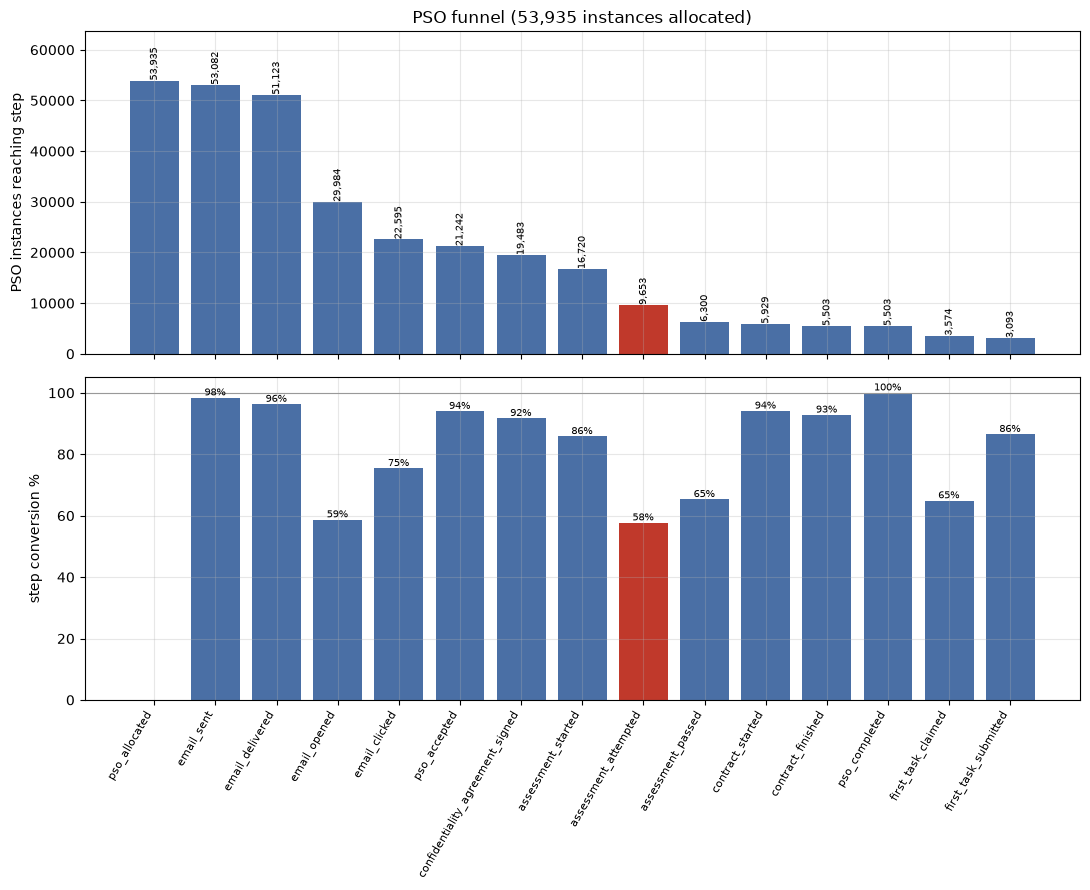

In [11]:
steps = pc.FUNNEL_STEPS
reached = funnel["reached"]
conv = funnel["step_conversion_pct"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
colors = ["#c0392b" if s == "assessment_attempted" else "#4a6fa5" for s in steps]
ax1.bar(range(len(steps)), reached, color=colors)
ax1.set_ylabel("PSO instances reaching step")
ax1.set_title("PSO funnel (53,935 instances allocated)")
for i, v in enumerate(reached):
    ax1.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7, rotation=90)
ax1.set_ylim(0, reached.max() * 1.18)

ax2.bar(range(len(steps)), conv, color=colors)
ax2.axhline(100, color="#999", lw=0.8)
ax2.set_ylabel("step conversion %")
ax2.set_xticks(range(len(steps)))
ax2.set_xticklabels(steps, rotation=60, ha="right", fontsize=8)
for i, v in enumerate(conv):
    if not np.isnan(v):
        ax2.text(i, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

Two candidates for "the biggest drop":

- `email_delivered → email_opened` loses **21,139** — the largest raw number, but the step
  we just showed is unreliable.
- `assessment_started → assessment_attempted` loses **7,067** at **57.7%** conversion — the
  worst conversion rate of any step in the funnel, and measured from server-side events we
  can trust.

Taking the assessment block as a whole, 16,720 people open an assessment and 6,300 pass:
**62% of everyone who reaches the assessment never gets through it.** That is the drop worth
attacking.

## 3. Why do people abandon the assessment?

The `properties` blob on `assessment_started` carries `session_seconds` and
`questions_answered`, which tells us what abandoners actually did.

In [12]:
started = inst[inst["reached_assessment_started"]]
abandoned = started[~started["reached_assessment_attempted"]]
attempted = started[started["reached_assessment_attempted"]]
total_abondoners = len(abandoned)
total_attempters = len(attempted)

print(f"Total abandonders: {total_abondoners}")
print(f"Total attempters: {total_attempters}")

summary = pd.DataFrame({
    "abandoned": abandoned[["assessment_session_seconds", "assessment_questions_answered"]].median(),
    "attempted": attempted[["assessment_session_seconds", "assessment_questions_answered"]].median(),
})
print("medians:")
print(summary.round(1).to_string())
print()
zero_q = int((abandoned["assessment_questions_answered"] == 0).sum())
print(f"abandoners answering ZERO questions: {zero_q:,} of {len(abandoned):,} "
      f"({zero_q / len(abandoned):.1%})")

Total abandonders: 7067
Total attempters: 9653
medians:
                               abandoned  attempted
assessment_session_seconds          92.0     1778.0
assessment_questions_answered        0.0       13.0

abandoners answering ZERO questions: 7,060 of 7,067 (99.9%)


In [13]:
# assessment_len = inst['assessment_est_minutes'].unique()
# print(sorted(assessment_len))

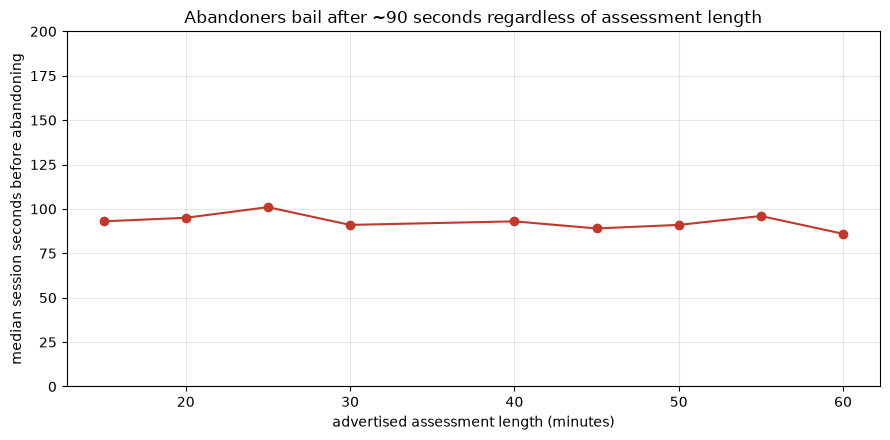

assessment_est_minutes
15     93.0
20     95.0
25    101.0
30     91.0
40     93.0
45     89.0
50     91.0
55     96.0
60     86.0
Name: assessment_session_seconds, dtype: float64

In [14]:
# Is the ~90 second bail-out a function of how long the assessment is?
by_len = abandoned.groupby("assessment_est_minutes")["assessment_session_seconds"].median()
fig, ax = plt.subplots()
ax.plot(by_len.index, by_len.values, "o-", color="#c0392b")
ax.set_xlabel("advertised assessment length (minutes)")
ax.set_ylabel("median session seconds before abandoning")
ax.set_ylim(0, 200)
ax.set_title("Abandoners bail after ~90 seconds regardless of assessment length")
plt.tight_layout()
plt.show()
by_len.round(0)

**This is the key finding.** Of the 7,067 instances that open an assessment and never attempt
it, **7,060 answered zero questions** (99.9%), and the median session is **92 seconds** — flat
across every assessment length from 15 to 60 minutes.

So this is not difficulty and not fatigue. Nobody is grinding through and giving up. People
open the assessment, look at it for about a minute and a half, answer nothing, and leave.
That is a bounce on the assessment landing screen, which points at a very different fix than
"make the questions easier".

### What predicts the bounce?

In [15]:
def attempt_rates(frame, by):
    g = frame.groupby(by, dropna=False).agg(
        starters=("reached_assessment_attempted", "size"),
        attempted=("reached_assessment_attempted", "sum"),
        passed=("reached_assessment_passed", "sum"),
    )
    ci = g.apply(lambda r: pc.wilson(int(r.attempted), int(r.starters)), axis=1)
    g["attempt_rate_pct"] = [round(c[0] * 100, 1) for c in ci]
    g["ci_low_pct"] = [round(c[1] * 100, 1) for c in ci]
    g["ci_high_pct"] = [round(c[2] * 100, 1) for c in ci]
    g["pass_rate_pct"] = (g["passed"] / g["starters"] * 100).round(1)
    
    # REMOVED: g.drop(columns=["attempted", "passed"])
    return g 

print("=== by advertised assessment length ===")
print(attempt_rates(started, "assessment_est_minutes").to_string())


=== by advertised assessment length ===
                        starters  attempted  passed  attempt_rate_pct  ci_low_pct  ci_high_pct  pass_rate_pct
assessment_est_minutes                                                                                       
15                          1528       1045     669              68.4        66.0         70.7           43.8
20                          3134       2122    1329              67.7        66.1         69.3           42.4
25                          1427        958     610              67.1        64.7         69.5           42.7
30                          2990       2009    1208              67.2        65.5         68.9           40.4
40                           863        368     263              42.6        39.4         46.0           30.5
45                          2963       1364     969              46.0        44.2         47.8           32.7
50                          1170        548     389              46.8        44.

In [16]:
# dropping the attempters and passers
def attempt_rates(frame, by):
    g = frame.groupby(by, dropna=False).agg(
        starters=("reached_assessment_attempted", "size"),
        attempted=("reached_assessment_attempted", "sum"),
        passed=("reached_assessment_passed", "sum"),
    )
    ci = g.apply(lambda r: pc.wilson(int(r.attempted), int(r.starters)), axis=1)
    g["attempt_rate_pct"] = [round(c[0] * 100, 1) for c in ci]
    g["ci_low_pct"] = [round(c[1] * 100, 1) for c in ci]
    g["ci_high_pct"] = [round(c[2] * 100, 1) for c in ci]
    g["pass_rate_pct"] = (g["passed"] / g["starters"] * 100).round(1)
    return g.drop(columns=["attempted", "passed"])

print("=== by advertised assessment length ===")
print(attempt_rates(started, "assessment_est_minutes").to_string())

=== by advertised assessment length ===
                        starters  attempt_rate_pct  ci_low_pct  ci_high_pct  pass_rate_pct
assessment_est_minutes                                                                    
15                          1528              68.4        66.0         70.7           43.8
20                          3134              67.7        66.1         69.3           42.4
25                          1427              67.1        64.7         69.5           42.7
30                          2990              67.2        65.5         68.9           40.4
40                           863              42.6        39.4         46.0           30.5
45                          2963              46.0        44.2         47.8           32.7
50                          1170              46.8        44.0         49.7           33.2
55                          1219              45.9        43.2         48.7           32.2
60                          1426              47.6

In [17]:
print("=== by device at assessment start ===")
print(attempt_rates(started, "assessment_device").to_string())

=== by device at assessment start ===
                   starters  attempt_rate_pct  ci_low_pct  ci_high_pct  pass_rate_pct
assessment_device                                                                    
desktop                5987              77.8        76.7         78.8           51.9
mobile                 7919              40.1        39.1         41.2           25.8
tablet                  724              59.7        56.1         63.2           39.4
NaN                    2090              66.3        64.2         68.3           41.3


In [18]:
for dim in ["country", "tasker_tenure", "concurrent_psos"]:
    print(f"=== by {dim} ===")
    print(attempt_rates(started, dim).to_string())
    print()

=== by country ===
         starters  attempt_rate_pct  ci_low_pct  ci_high_pct  pass_rate_pct
country                                                                    
BR           1220              56.4        53.6         59.2           36.1
CA           1269              56.5        53.8         59.2           36.5
DE           1159              58.2        55.3         61.0           36.2
GB           1224              57.9        55.1         60.7           38.2
IN           1204              58.6        55.8         61.4           38.5
KE           1169              56.3        53.4         59.1           35.8
NG           1082              58.4        55.4         61.3           38.1
PH           1313              58.9        56.3         61.6           37.6
US           7080              57.8        56.7         59.0           38.4

=== by tasker_tenure ===
               starters  attempt_rate_pct  ci_low_pct  ci_high_pct  pass_rate_pct
tasker_tenure                        

Two drivers stand out, and three candidates are ruled out.

**Assessment length — a cliff, not a slope.** 15/20/25/30-minute assessments all sit at
67–68% attempt rate. 40/45/50/55/60-minute assessments all sit at 43–48%. The step change
happens between 30 and 40 minutes; inside each group, length barely matters. `est_minutes`
is fixed per project, so this is a project-design lever.

**Device — the single largest effect.** Desktop 77.8%, tablet 59.7%, mobile **40.1%**. A
38-point gap, and mobile is the largest group of starters (47.4% of all starters, 54.1% of those with a device recorded; see appendix).

**Not drivers:** country spans 56.3–58.9%, tenure 57.1% vs 58.5%, and concurrent PSOs shows
no consistent trend: 1 and 2 sit at 58.7% and 57.0%, 3 dips to 47.1% (n = 923), and 4 and 5
are too small to read (n = 186 and 55) and point in opposite directions. Prior projects
completed is identical to tenure in this data (see appendix C), so it is covered by the tenure
split. Worth stating explicitly — a story about inexperienced taskers is not what the data
shows, and a story about overloaded taskers has no consistent support either.

In [19]:
# Do length and device act independently, or is one standing in for the other?
pivot = started.pivot_table(
    index="assessment_device", columns="assessment_length_bucket",
    values="reached_assessment_attempted", aggfunc=["mean", "size"])
print("attempt rate and n, device x length:")
print(pivot.round(3).to_string())
print()
mix = (started.groupby("assessment_est_minutes")["assessment_device"]
       .value_counts(normalize=True).unstack())
print("device mix by assessment length (is mobile concentrated in long assessments?):")
print(mix.round(3).to_string())

attempt rate and n, device x length:
                            mean                 size             
assessment_length_bucket 40+ min under 40 min 40+ min under 40 min
assessment_device                                                 
desktop                    0.732        0.827    3070         2917
mobile                     0.250        0.561    4068         3851
tablet                     0.520        0.681     379          345

device mix by assessment length (is mobile concentrated in long assessments?):
assessment_device       desktop  mobile  tablet
assessment_est_minutes                         
15                        0.434   0.513   0.052
20                        0.419   0.532   0.049
25                        0.392   0.564   0.044
30                        0.376   0.576   0.048
40                        0.356   0.593   0.051
45                        0.407   0.541   0.052
50                        0.429   0.523   0.048
55                        0.381   0.569   0.050
6

They act independently and they compound. Mobile's share of starters is a flat 50–59% across
every assessment length, so neither variable is a proxy for the other. The corners:

| | under 40 min | 40+ min |
|---|---|---|
| **desktop** | **82.7%** | 73.2% |
| **mobile** | 56.1% | **25.0%** |

A mobile tasker facing a 45-minute assessment has a one-in-four chance of answering a single
question. The same assessment on desktop is three times better.

In [20]:
# Instances that start the assessment more than once.
multi = started.groupby("assessment_starts")["reached_assessment_attempted"].agg(["size", "mean"])
multi.columns = ["instances", "attempt_rate"]
multi["attempt_rate"] = (multi["attempt_rate"] * 100).round(1)
print(multi.to_string())

                   instances  attempt_rate
assessment_starts                         
1                      15241          56.1
2                       1479          74.1


1,479 instances start the assessment twice, and they attempt at **74.1%** against 56.1% for
single-start instances. This is correlational — people who come back were probably more
motivated to begin with — but it is consistent with coming back later being a viable path,
which matters for the "make it resumable" recommendation.

## 4. Right-censoring

The export is dated September 1. Instances allocated in late August have not had time to
finish, so their outcomes are missing rather than negative.

In [21]:
by_week = inst.groupby("alloc_week").agg(
    instances=("reached_pso_allocated", "size"),
    accept_pct=("reached_pso_accepted", "mean"),
    complete_pct=("reached_pso_completed", "mean"),
)
by_week["accept_pct"] = (by_week["accept_pct"] * 100).round(1)
by_week["complete_pct"] = (by_week["complete_pct"] * 100).round(1)
print(by_week.to_string())

lag = pd.DataFrame({
    step: ((inst[f"ts_{step}"] - inst["ts_pso_allocated"]).dt.total_seconds() / 86400).describe(
        percentiles=[0.5, 0.9])
    for step in ["pso_accepted", "assessment_started", "assessment_passed", "pso_completed"]
}).T[["50%", "90%", "max"]].round(2)
print()
print("days from allocation to step (reachers only):")
print(lag.to_string())

            instances  accept_pct  complete_pct
alloc_week                                     
2026-06-01       1771        39.9          11.5
2026-06-08       2530        38.7          11.3
2026-06-15       3071        40.0          10.8
2026-06-22       3405        40.5          12.6
2026-06-29       3758        39.6          11.0
2026-07-06       4142        39.5          10.2
2026-07-13       4366        39.5          10.6
2026-07-20       4620        39.8          10.7
2026-07-27       4844        40.2          10.8
2026-08-03       5009        39.6          10.1
2026-08-10       5363        39.1          10.4
2026-08-17       5337        39.1           9.9
2026-08-24       5047        39.4           6.7
2026-08-31        672        24.3           0.1

days from allocation to step (reachers only):
                     50%   90%    max
pso_accepted        0.20  1.28  37.11
assessment_started  0.47  2.04  31.18
assessment_passed   2.24  7.13  34.48
pso_completed       2.64  7.80  3

Completion sits at 9.9–12.6% every week through the week of August 17, then falls to 6.7% and 0.1% — purely
an artifact of the extract date, since p90 time to complete is 7.8 days. Acceptance stays
flat at 38.7–40.5% through the week of August 24 because accepts happen within a day of allocation and are unaffected.

So: top-of-funnel rates can use all the data; anything past the assessment should exclude
instances allocated in the last 7 days. The dashboard exposes this as a toggle, defaulted off so its opening numbers match this notebook.

In [22]:
mature_funnel = pc.funnel_table(inst[inst["mature"]])
comparison = pd.DataFrame({
    "all_pct_of_allocated": funnel["pct_of_allocated"],
    "mature_only_pct_of_allocated": mature_funnel["pct_of_allocated"],
})
comparison["difference"] = (comparison.iloc[:, 1] - comparison.iloc[:, 0]).round(1)
print(f"mature instances: {int(inst['mature'].sum()):,} of {len(inst):,}")
print(comparison.to_string())

mature instances: 48,934 of 53,935
                                  all_pct_of_allocated  mature_only_pct_of_allocated  difference
pso_allocated                                    100.0                         100.0         0.0
email_sent                                        98.4                          98.4         0.0
email_delivered                                   94.8                          94.8         0.0
email_opened                                      55.6                          55.6         0.0
email_clicked                                     41.9                          42.1         0.2
pso_accepted                                      39.4                          39.6         0.2
confidentiality_agreement_signed                  36.1                          36.3         0.2
assessment_started                                31.0                          31.3         0.3
assessment_attempted                              17.9                          18.4        

Excluding immature cohorts lifts end-to-end completion from 10.2% to 10.7%. The censoring is
real but modest — it changes the number, not the conclusion.

## 5. The leak after PSO

In [23]:
completed = int(inst["reached_pso_completed"].sum())
claimed = int(inst["reached_first_task_claimed"].sum())
submitted = int(inst["reached_first_task_submitted"].sum())
print(f"pso_completed       : {completed:,}")
print(f"first_task_claimed  : {claimed:,}  ({claimed / completed:.1%} of completers)")
print(f"first_task_submitted: {submitted:,}  ({submitted / completed:.1%} of completers)")
print(f"\nfully onboarded, never claimed work: {completed - claimed:,}")

pso_completed       : 5,503
first_task_claimed  : 3,574  (64.9% of completers)
first_task_submitted: 3,093  (56.2% of completers)

fully onboarded, never claimed work: 1,929


1,929 taskers clear every PSO gate and never claim a task — 35% of everyone we successfully
onboard. That is outside the funnel we were asked about, but it is delivered capacity
evaporating after we have already paid the full onboarding cost, and it is a bigger absolute
loss than the contract steps. Flagging it; the data does not say why.

## 6. The likeness agreement pilot

Piloted on three projects. `likeness_variant` splits each into `early` and `late`; the
`placement` property on signed agreements says what those mean.

In [24]:
pilot = inst[inst["likeness_variant"].notna()]
print("projects and arm sizes:")
print(pd.crosstab(pilot["project_name"], pilot["likeness_variant"]).to_string())
print()
print("placement recorded on signed agreements, by arm:")
print(pd.crosstab(pilot["likeness_variant"], pilot["likeness_placement"]).to_string())

projects and arm sizes:
likeness_variant  early  late
project_name                 
Lumen              2090  2127
Orchid             1996  2099
Vesper             2001  2034

placement recorded on signed agreements, by arm:
likeness_placement  after_accept  with_contract
likeness_variant                               
early                       2017              0
late                           0            598


A clean randomised A/B on Lumen, Orchid and Vesper, split ~50/50 (6,087 early vs 6,260 late).
`early` = `after_accept`, immediately after the invitation is accepted and before the
confidentiality agreement. `late` = `with_contract`, at the very end.

In [25]:
arms = {a: pilot[pilot["likeness_variant"] == a] for a in ["early", "late"]}
rows = []
for step in pc.FUNNEL_STEPS + pc.LIKENESS_STEPS:
    e, l = arms["early"], arms["late"]
    xe, ne = int(e[f"reached_{step}"].sum()), len(e)
    xl, nl = int(l[f"reached_{step}"].sum()), len(l)
    t = pc.two_proportion_z(xe, ne, xl, nl)
    rows.append({
        "step": step, "early_n": xe, "early_pct": round(t["p1"] * 100, 2),
        "late_n": xl, "late_pct": round(t["p2"] * 100, 2),
        "diff_pp": round(t["diff"] * 100, 2), "z": round(t["z"], 2),
        "p_value": round(t["p_value"], 4),
    })
ab = pd.DataFrame(rows).set_index("step")
ab

,early_n,early_pct,late_n,late_pct,diff_pp,z,p_value
step,,,,,,,
pso_allocated,6087,100.00,6260,100.00,0.00,NaN,NaN
email_sent,5985,98.32,6174,98.63,-0.30,-1.37,0.1708
email_delivered,5745,94.38,5937,94.84,-0.46,-1.13,0.2589
email_opened,3250,53.39,3410,54.47,-1.08,-1.20,0.2286
email_clicked,2452,40.28,2613,41.74,-1.46,-1.65,0.0995
pso_accepted,2301,37.80,2472,39.49,-1.69,-1.92,0.0543
confidentiality_agreement_signed,1878,30.85,2291,36.60,-5.74,-6.75,0.0000
assessment_started,1594,26.19,1999,31.93,-5.75,-7.03,0.0000
assessment_attempted,858,14.10,1012,16.17,-2.07,-3.21,0.0013


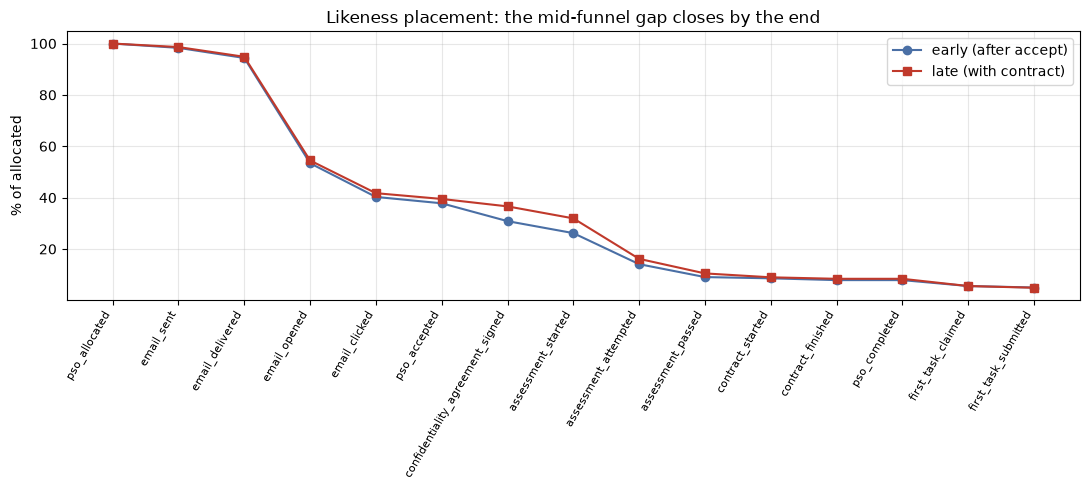

In [26]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(pc.FUNNEL_STEPS))
sub = ab.loc[pc.FUNNEL_STEPS]
ax.plot(x, sub["early_pct"], "o-", label="early (after accept)", color="#4a6fa5")
ax.plot(x, sub["late_pct"], "s-", label="late (with contract)", color="#c0392b")
ax.set_xticks(x)
ax.set_xticklabels(pc.FUNNEL_STEPS, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("% of allocated")
ax.set_title("Likeness placement: the mid-funnel gap closes by the end")
ax.legend()
plt.tight_layout()
plt.show()

Mid-funnel, early placement looks clearly worse: 5.7 points fewer confidentiality agreements
(z = −6.8) and 2.1 points fewer assessment attempts (z = −3.2). Both comfortably significant.

But the gap closes completely by the end. `pso_completed` differs by 0.5 points (z = −1.05,
not significant) and **`first_task_submitted` is a dead heat: 305 versus 308 taskers,
z = +0.23**. The extra people that late placement carries through the middle of the funnel
do not turn into productive taskers.

In [27]:
# What did each arm's decliners already invest before declining?
for arm, frame in arms.items():
    d = frame[frame["reached_likeness_agreement_declined"]]
    print(f"{arm}: {len(d)} declined | "
          f"{int(d['reached_assessment_started'].sum())} had started the assessment | "
          f"{int(d['reached_assessment_passed'].sum())} had PASSED it")

print()
for arm, frame in arms.items():
    signed = int(frame["reached_likeness_agreement_signed"].sum())
    declined = int(frame["reached_likeness_agreement_declined"].sum())
    print(f"{arm}: reached the gate {signed + declined:,}, "
          f"declined {declined} ({declined / (signed + declined):.1%})")

early: 283 declined | 0 had started the assessment | 0 had PASSED it
late: 52 declined | 52 had started the assessment | 52 had PASSED it

early: reached the gate 2,300, declined 283 (12.3%)
late: reached the gate 650, declined 52 (8.0%)


In [28]:
# Was the pilot big enough to detect a difference that would matter?
base = pilot["reached_pso_completed"].mean()
mde = pc.minimum_detectable_effect(base, len(arms["early"]), len(arms["late"]))
print(f"baseline pso_completed: {base:.2%}")
print(f"minimum detectable effect (80% power, alpha=0.05): {mde * 100:.2f}pp")
print(f"observed difference: {ab.loc['pso_completed', 'diff_pp']:.2f}pp")

baseline pso_completed: 8.15%
minimum detectable effect (80% power, alpha=0.05): 1.38pp
observed difference: -0.52pp


**Decision: put the likeness agreement early, right after accept.**

- Delivered capacity is identical either way — 305 vs 308 first tasks submitted.
- Every one of the 52 late-arm decliners **had already passed the assessment**. Their entire
  qualification effort was wasted, and we lost them at the final gate. In the early arm, not
  one decliner had touched the assessment.
- Asking early converts a late, expensive loss into a cheap one, at no cost to output.

Two honest caveats. The pilot could only detect a difference of about 1.4pp in completion, so
"no difference" means "none large enough to matter", not "provably zero". And the gate-level
decline rates (12.3% early vs 8.0% late) are **not** comparable: the late arm only asks people
who already survived the assessment, so it is measuring a pre-selected group.

## Summary

| | |
|---|---|
| **Biggest trustworthy drop** | `assessment_started → assessment_attempted`: 7,067 lost, 57.7% conversion |
| **Mechanism** | 7,060 of 7,067 abandoners answered **zero** questions, median 92s — a landing-screen bounce |
| **Driver 1** | Length cliff at 40 min: 67–68% attempt under, 43–48% over |
| **Driver 2** | Device: desktop 77.8% vs mobile 40.1%, mobile is 47.4% of starters |
| **Compounded** | mobile × 40+ min = 25.0%; desktop × under 40 = 82.7% |
| **Ruled out** | country, tenure / prior projects (identical in this data); concurrent PSOs shows no consistent trend |
| **Likeness** | Place early: identical output, eliminates wasted qualification work |

Recommendations and measurement plan are in `../FINDINGS.md`.

## Appendix: supporting checks

Figures quoted in `FINDINGS.md` and `Journal.md` that the sections above do not print. Nothing here changes the cleaning or the funnel logic; it only makes every quoted number traceable to an output in this notebook.

### A. Reconciling raw event counts with the instance table

The raw event counts in section 1 (e.g. 54,473 `pso_allocated`) do not match the funnel (53,935 allocated). Count each event three ways to see where the gap goes.

In [29]:
import csv
from collections import Counter, defaultdict

# Reconcile the three ways of counting each event: raw rows, rows after dropping
# repeated event_ids, and PSO instances that reached the step.
csv.field_size_limit(sys.maxsize)
seen, deduped = set(), Counter()
prop_values = defaultdict(Counter)
with open(PATH, newline="", encoding="utf-8") as fh:
    for row in csv.DictReader(fh):
        if row["event_id"] in seen:
            continue
        seen.add(row["event_id"])
        deduped[row["event_name"]] += 1
        if row["properties"]:
            for k, v in json.loads(row["properties"]).items():
                if isinstance(v, str):
                    prop_values[(row["event_name"], k)][v] += 1

recon = pd.DataFrame({
    "raw_rows": pd.Series(qa["event_counts"]),
    "deduped_events": pd.Series(deduped),
    "instances_reached": pd.Series({s: int(inst["reached_" + s].sum())
                                    for s in pc.FUNNEL_STEPS + pc.LIKENESS_STEPS}),
})
recon["replayed_rows"] = recon["raw_rows"] - recon["deduped_events"]
recon["repeat_events_per_instance"] = recon["deduped_events"] - recon["instances_reached"]
print(recon.sort_values("raw_rows", ascending=False).to_string())
print()
print(recon[["replayed_rows", "repeat_events_per_instance"]].sum().to_string())
print(f"second assessment starts (instances with assessment_starts == 2): "
      f"{int((inst['assessment_starts'] == 2).sum()):,}")

                                  raw_rows  deduped_events  instances_reached  replayed_rows  repeat_events_per_instance
pso_allocated                        54473           53935              53935            538                           0
email_sent                           53635           53082              53082            553                           0
email_delivered                      51594           51123              51123            471                           0
email_opened                         30301           29984              29984            317                           0
email_clicked                        22805           22595              22595            210                           0
pso_accepted                         21468           21242              21242            226                           0
confidentiality_agreement_signed     19664           19483              19483            181                           0
assessment_started              

Every gap is one of two things. 3,121 rows are pipeline replays, removed by de-duplicating on `event_id`. The remaining 1,479 are genuine second `assessment_started` events: real return visits, which the instance table keeps as `assessment_starts == 2`. No other step ever occurs twice for the same instance, so the funnel's `reached_*` flags are unaffected by duplicates.

### B. Categorical values inside `properties`

In [30]:
print("categorical values inside `properties`, deduped events:")
for (event, key), counts in sorted(prop_values.items()):
    print(f"  {event:28s} {key:10s} {dict(counts)}")

categorical values inside `properties`, deduped events:
  email_clicked                cta        {'view_project': 22595}
  email_sent                   template   {'pso_invite_v3': 53082}
  likeness_agreement_signed    placement  {'after_accept': 2017, 'with_contract': 598}
  pso_accepted                 source     {'email': 19541, 'in_app': 1701}


### C. Tasker attributes

In [31]:
per_tasker = inst.groupby("tasker_id").size()
print(f"taskers with more than one PSO instance: {int((per_tasker > 1).sum()):,} of {len(per_tasker):,}")
print(f"most PSO instances held by one tasker  : {per_tasker.max()}")
print(f"max distinct countries per tasker      : {inst.groupby('tasker_id')['country'].nunique().max()}")
print(f"US share of instances                  : {(inst['country'] == 'US').mean():.1%}")
print(f"prior_projects_completed range         : {inst['prior_projects_completed'].min()}-{inst['prior_projects_completed'].max()}")
print()
print("tenure vs prior projects completed:")
print(pd.crosstab(inst["tasker_tenure"], inst["prior_projects_completed"] > 0,
                  colnames=["prior_projects_completed > 0"]).to_string())

taskers with more than one PSO instance: 14,344 of 30,025
most PSO instances held by one tasker  : 6
max distinct countries per tasker      : 1
US share of instances                  : 42.6%
prior_projects_completed range         : 0-10

tenure vs prior projects completed:
prior_projects_completed > 0  False  True 
tasker_tenure                             
new                           28091      0
returning                         0  25844


### D. Per-project view: assessment length, device coverage, device gap

In [32]:
by_project = inst.groupby("project_name").agg(
    est_minutes_values=("assessment_est_minutes", "nunique"),
    est_minutes=("assessment_est_minutes", "first"),
    instances=("tasker_id", "size"),
)
dev = started.groupby("project_name").agg(
    starters=("tasker_id", "size"),
    device_unrecorded=("assessment_device", lambda s: int(s.isna().sum())),
)
rate = started.pivot_table(index="project_name", columns="assessment_device",
                           values="reached_assessment_attempted", aggfunc="mean")
by_project = by_project.join(dev).join((rate * 100).round(1).add_suffix("_attempt_pct"))
by_project["desktop_minus_mobile_pp"] = (by_project["desktop_attempt_pct"]
                                         - by_project["mobile_attempt_pct"]).round(1)
print(by_project.sort_values("est_minutes").to_string())
gap = by_project["desktop_minus_mobile_pp"].dropna()
print(f"\nprojects with device recorded: {len(gap)}; desktop - mobile gap ranges "
      f"{gap.min():.1f} to {gap.max():.1f}pp; projects where mobile wins: {int((gap < 0).sum())}")
print(f"starters with no device recorded: {int(started['assessment_device'].isna().sum()):,}")

              est_minutes_values  est_minutes  instances  starters  device_unrecorded  desktop_attempt_pct  mobile_attempt_pct  tablet_attempt_pct  desktop_minus_mobile_pp
project_name                                                                                                                                                               
Meridian                       1           15       4907      1528                 34                 82.0                56.6                66.7                     25.4
Granite                        1           20       3453      1046                 17                 83.8                57.4                70.2                     26.4
Juniper                        1           20       6401      2088                 37                 81.9                55.8                66.3                     26.1
Sequoia                        1           25       4650      1427                 27                 86.0                54.1              

Each project has exactly one advertised assessment length, so length cannot be separated from project. Device does vary within every project, and desktop beats mobile in all 11 projects where device is recorded. The gap is roughly twice as large on 40+ minute projects (44.1–50.9pp) as on shorter ones (22.9–31.9pp), which is the device × length compounding seen in section 3. Quartz records no device on any of its 1,835 starters.

### E. Email tracking gap and assessment scores

In [33]:
later = pc.FUNNEL_STEPS[pc.FUNNEL_STEPS.index("email_opened") + 1:]
any_later = inst[["reached_" + s for s in later]].any(axis=1)
print(f"instances reaching a step after email_opened with no recorded open: "
      f"{int((any_later & ~inst['reached_email_opened']).sum()):,}")
print(f"  of which reached pso_accepted: {int((inst['reached_pso_accepted'] & ~inst['reached_email_opened']).sum()):,}")
score = inst["assessment_score"].dropna()
print(f"assessment_score: recorded on {len(score):,} instances (passed = {int(inst['reached_assessment_passed'].sum()):,}), "
      f"min {score.min():.2f}, mean {score.mean():.2f}, max {score.max():.2f}")

instances reaching a step after email_opened with no recorded open: 2,470
  of which reached pso_accepted: 2,311
assessment_score: recorded on 6,300 instances (passed = 6,300), min 0.67, mean 0.81, max 1.00


### F. Are the taskers lost on mobile less capable? And the size of the prize

In [34]:
# Are the taskers lost on mobile less capable? Pass rate among those who attempt.
attempted = started[started["reached_assessment_attempted"]]
print("pass rate among those who attempted, by device:")
print((attempted.groupby("assessment_device")["reached_assessment_passed"].mean() * 100).round(1).to_string())

# Size of the prize: close half the desktop-mobile attempt gap, then carry the extra
# attempts through the observed mobile pass rate and passed -> completed rate.
dev_rate = started.groupby("assessment_device")["reached_assessment_attempted"].mean()
mobile_starters = int((started["assessment_device"] == "mobile").sum())
extra_attempts = mobile_starters * (dev_rate["desktop"] - dev_rate["mobile"]) / 2
mobile_pass = attempted.loc[attempted["assessment_device"] == "mobile", "reached_assessment_passed"].mean()
passed_to_completed = inst["reached_pso_completed"].sum() / inst["reached_assessment_passed"].sum()
extra_completed = extra_attempts * mobile_pass * passed_to_completed
completed = int(inst["reached_pso_completed"].sum())
print()
print(f"mobile starters                    : {mobile_starters:,} "
      f"({mobile_starters / len(started):.1%} of all starters, "
      f"{mobile_starters / started['assessment_device'].notna().sum():.1%} of starters with a device)")
print(f"half the desktop-mobile gap        : {(dev_rate['desktop'] - dev_rate['mobile']) / 2 * 100:.1f}pp")
print(f"extra attempts                     : {extra_attempts:,.0f}")
print(f"x mobile pass rate {mobile_pass:.1%} x passed->completed {passed_to_completed:.1%}")
print(f"extra completed PSOs               : {extra_completed:,.0f}  (+{extra_completed / completed:.1%} on {completed:,})")

pass rate among those who attempted, by device:
assessment_device
desktop    66.7
mobile     64.4
tablet     66.0

mobile starters                    : 7,919 (47.4% of all starters, 54.1% of starters with a device)
half the desktop-mobile gap        : 18.8pp
extra attempts                     : 1,492
x mobile pass rate 64.4% x passed->completed 87.3%
extra completed PSOs               : 839  (+15.2% on 5,503)


### G. Sizing a follow-up test on the primary metric

In [35]:
# How long would a mobile-only A/B on the primary metric need to run?
base = dev_rate["mobile"]
for months in (1, 3):
    per_arm = mobile_starters / 3 * months / 2
    mde = pc.minimum_detectable_effect(base, int(per_arm), int(per_arm))
    print(f"{months} month(s): ~{per_arm:,.0f} mobile starters per arm -> "
          f"detects {mde * 100:.1f}pp on a {base:.1%} baseline (80% power, alpha=0.05)")

1 month(s): ~1,320 mobile starters per arm -> detects 5.3pp on a 40.1% baseline (80% power, alpha=0.05)
3 month(s): ~3,960 mobile starters per arm -> detects 3.1pp on a 40.1% baseline (80% power, alpha=0.05)


### H. Which funnel steps can ever show more than 100% conversion?

For each consecutive pair of steps, count instances that reached the later step without the earlier one. Where that count is zero, no filter on the dashboard can push that step above 100%.

In [36]:
skips = pd.Series({
    f"{a} -> {b}": int((inst["reached_" + b] & ~inst["reached_" + a]).sum())
    for a, b in zip(pc.FUNNEL_STEPS, pc.FUNNEL_STEPS[1:])
}, name="reached later step without the earlier one")
print(skips.to_string())
acc_no_click = inst["reached_pso_accepted"] & ~inst["reached_email_clicked"]
in_app = inst["accept_source"] == "in_app"
print(f"\naccepted with no recorded click: {int(acc_no_click.sum()):,}; accepted in-app: {int(in_app.sum()):,}; "
      f"same instances: {bool((acc_no_click == in_app).all())}")

pso_allocated -> email_sent                                  0
email_sent -> email_delivered                                0
email_delivered -> email_opened                              0
email_opened -> email_clicked                             1272
email_clicked -> pso_accepted                             1701
pso_accepted -> confidentiality_agreement_signed             0
confidentiality_agreement_signed -> assessment_started       0
assessment_started -> assessment_attempted                   0
assessment_attempted -> assessment_passed                    0
assessment_passed -> contract_started                        0
contract_started -> contract_finished                        0
contract_finished -> pso_completed                           0
pso_completed -> first_task_claimed                          0
first_task_claimed -> first_task_submitted                   0

accepted with no recorded click: 1,701; accepted in-app: 1,701; same instances: True
